# PPG-DaLiA — 01. Exploratory Data Analysis

**Goal:** Explore the participants first, choose one, and inspect their wrist PPG and accelerometer signals. No heart-rate model is built here.

The dataset contains 15 participants, wrist BVP/PPG (64 Hz), wrist accelerometer (32 Hz), and ECG-derived reference heart-rate labels (8-second windows, shifted by 2 seconds).

Sources: [UCI PPG-DaLiA](https://archive.ics.uci.edu/dataset/495/ppg-dalia) · [Original paper](https://doi.org/10.3390/s19143079).

## 1. Meet the participants

The following small table comes from the **published PPG-DaLiA participant characteristics** ([Papaleonidas et al., Table 2](https://doi.org/10.1080/24751839.2021.1987706)). It is included here so you can compare the 15 subjects **before loading a large `.pkl` file**.

- **Skin type:** Fitzpatrick classification reported by the study.
- **Fitness:** 1–6 (1 = exercises less than once/month; 6 = exercises 5–7 times/week).

These are reported participant attributes, not values measured by the wrist sensors.

In [57]:
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Subject metadata transcribed from the published dataset table.
subjects = pd.DataFrame([
    ["S1",  "Male",   34, 182,  78, 3, 6],
    ["S2",  "Male",   28, 189,  80, 3, 5],
    ["S3",  "Male",   25, 170,  60, 3, 5],
    ["S4",  "Male",   25, 168,  57, 4, 5],
    ["S5",  "Female", 21, 180,  70, 3, 4],
    ["S6",  "Female", 37, 176,  70, 3, 1],
    ["S7",  "Female", 21, 168,  58, 3, 2],
    ["S8",  "Male",   43, 179,  70, 3, 5],
    ["S9",  "Female", 28, 167,  60, 4, 5],
    ["S10", "Female", 55, 164,  56, 4, 5],
    ["S11", "Female", 24, 168,  62, 3, 5],
    ["S12", "Male",   43, 195, 105, 3, 5],
    ["S13", "Female", 21, 170,  63, 3, 6],
    ["S14", "Female", 26, 170,  67, 3, 4],
    ["S15", "Male",   28, 183,  79, 2, 5],
], columns=["Subject", "Gender", "Age", "Height (cm)", "Weight (kg)", "Skin type", "Fitness"])

display(subjects)
print(f"Subjects: {len(subjects)}")
print(f"Age: {subjects['Age'].min()}–{subjects['Age'].max()} years (median {subjects['Age'].median():.0f})")
print("Gender distribution:")
print(subjects["Gender"].value_counts().to_string())


# Notes:
# - our skin is typically 3, 4. so this dataset is good for that
# - I'll focus more on younger subjects, as those are more closely related to our product.
# - There are more male kids than female kids, so I'll test more males.

# based on that, S3 and S4 are the best candidates
# wl 7lw en el nas dyh m3ndhash mshakel, fy nas tanya gehazha baz
# fy nas m3mletsh el tadreeb kamel

,Subject,Gender,Age,Height (cm),Weight (kg),Skin type,Fitness
0,S1,Male,34,182,78,3,6
1,S2,Male,28,189,80,3,5
2,S3,Male,25,170,60,3,5
3,S4,Male,25,168,57,4,5
4,S5,Female,21,180,70,3,4
5,S6,Female,37,176,70,3,1
6,S7,Female,21,168,58,3,2
7,S8,Male,43,179,70,3,5
8,S9,Female,28,167,60,4,5
9,S10,Female,55,164,56,4,5


Subjects: 15
Age: 21–55 years (median 28)
Gender distribution:
Gender
Female    8
Male      7


### Age and gender distributions

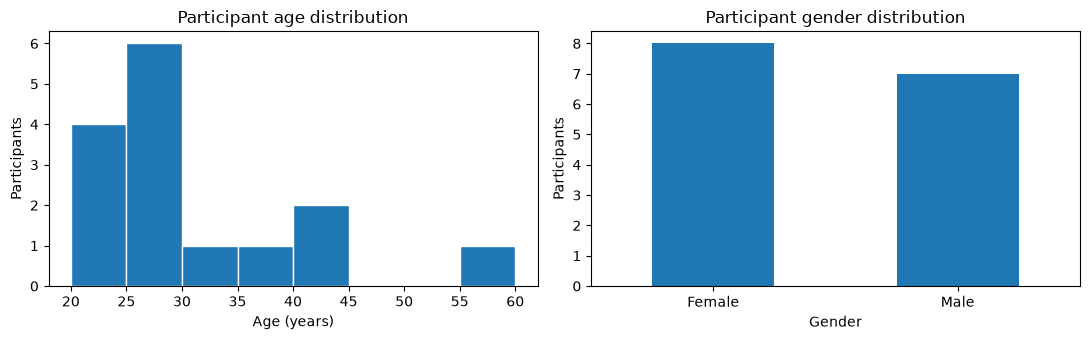

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))

axes[0].hist(subjects["Age"], bins=range(20, 61, 5), edgecolor="white")
axes[0].set(title="Participant age distribution", xlabel="Age (years)", ylabel="Participants")

subjects["Gender"].value_counts().plot.bar(ax=axes[1], rot=0)
axes[1].set(title="Participant gender distribution", xlabel="Gender", ylabel="Participants")

plt.tight_layout()
plt.show()

### Skin type and fitness distributions

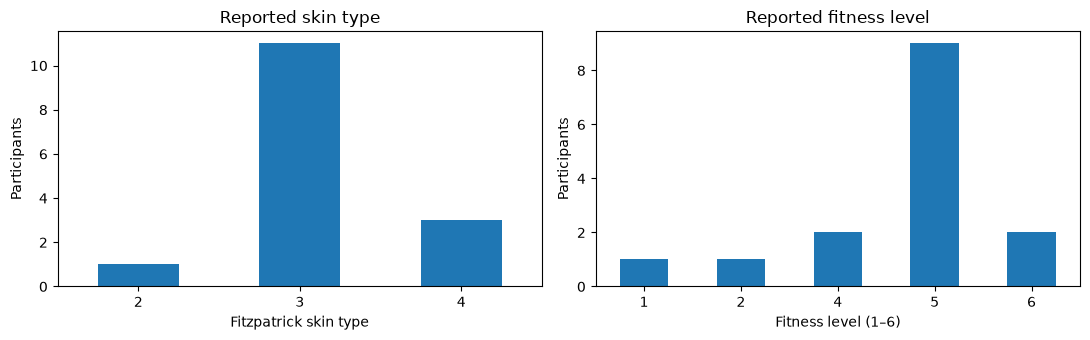

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))

subjects["Skin type"].value_counts().sort_index().plot.bar(ax=axes[0], rot=0)
axes[0].set(title="Reported skin type", xlabel="Fitzpatrick skin type", ylabel="Participants")

subjects["Fitness"].value_counts().sort_index().plot.bar(ax=axes[1], rot=0)
axes[1].set(title="Reported fitness level", xlabel="Fitness level (1–6)", ylabel="Participants")

plt.tight_layout()
plt.show()

## 2. Choose a participant

Change only `SUBJECT` to examine someone else. `DATA_FOLDER` should point to the extracted folder containing `S1/`, `S2/`, etc. The relative path below assumes the notebook lives in `notebooks/` and the extracted dataset lives in `data/PPG_FieldStudy/`.

**Suggested first choice:** S1 is a reasonable starting point. S6 has a shortened recording because of a hardware issue; S5 has unusually high average reference heart rate in the original study. Those can make useful comparisons later.

In [60]:
SUBJECT = "S4"
SUBJECT = "S1"
DATA_FOLDER = Path("../Data/PPG_FieldStudy")

# Show the selected participant's published metadata.
display(subjects[subjects["Subject"] == SUBJECT])

,Subject,Gender,Age,Height (cm),Weight (kg),Skin type,Fitness
0,S1,Male,34,182,78,3,6


## 3. Load the selected person's recordings

We load the wrist BVP/PPG, the wrist accelerometer, and the reference HR labels. **Reference HR is for exploration and later evaluation only; it must never be used to calculate the PPG estimate.**

**Security note:** Python pickle can execute code while loading. Only open `.pkl` files from the trusted official dataset, preferably in an isolated environment.

In [61]:
file = DATA_FOLDER / SUBJECT / f"{SUBJECT}.pkl"
with open(file, "rb") as f:
    data = pickle.load(f, encoding="latin1")

ppg = np.asarray(data["signal"]["wrist"]["BVP"]).flatten()
acc = np.asarray(data["signal"]["wrist"]["ACC"])
reference_hr = np.asarray(data["label"]).flatten()

PPG_HZ = 64
ACC_HZ = 32

print("PPG shape:", ppg.shape)
print("Accelerometer shape:", acc.shape)
print("Reference HR labels:", reference_hr.shape)

PPG shape: (589568,)
Accelerometer shape: (294784, 3)
Reference HR labels: (4603,)


### Sampling rates, durations, and missing values

In [62]:
summary = pd.DataFrame([
    ["Wrist PPG", len(ppg), PPG_HZ, len(ppg) / PPG_HZ / 60, np.size(ppg) - np.isfinite(ppg).sum()],
    ["Wrist ACC", len(acc), ACC_HZ, len(acc) / ACC_HZ / 60, np.size(acc) - np.isfinite(acc).sum()],
], columns=["Signal", "Samples", "Sampling rate (Hz)", "Duration (minutes)", "Non-finite values"])

display(summary.round(2))
print(f"Reference HR: {len(reference_hr)} labels, {np.size(reference_hr) - np.isfinite(reference_hr).sum()} non-finite values")
print("Each reference label summarizes an 8-second window; labels are spaced 2 seconds apart.")

,Signal,Samples,Sampling rate (Hz),Duration (minutes),Non-finite values
0,Wrist PPG,589568,64,153.53,0
1,Wrist ACC,294784,32,153.53,0


Reference HR: 4603 labels, 0 non-finite values
Each reference label summarizes an 8-second window; labels are spaced 2 seconds apart.


## 4. Plot a short wrist-signal segment

An entire 2.5-hour recording is too dense to inspect in one plot. Start with 20 seconds; change `START` and `DURATION` to inspect other intervals.

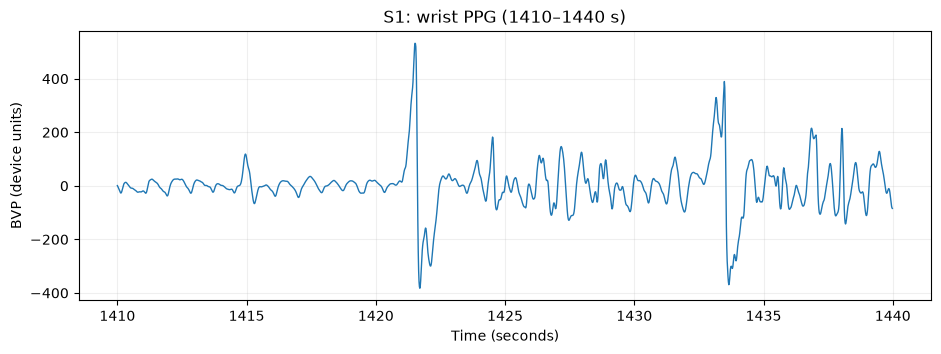

In [81]:
timeline = {"NO:_ACTIVITY1":	0,
 "BASELINE":	90,
 "NO_ACTIVITY2":	791,
 "STAIRS":	837,
 "NO_ACTIVITY3":	1125,
 "SOCCER":	1210,
 "NO_ACTIVITY4":	1556,
 "CYCLING":	1918,
 "NO_ACTIVITY5":	2331,
 "DRIVING":	2935,
 "NO_ACTIVITY6":	3825,
 "LUNCH":	4595,
 "WALKING":	6951,
 "NO_ACTIVITY7":	7706,
 "WORKING":	7791,
 "NO_ACTIVITY8":	8981,
 "CLEAN_BASELINE":	9077,
 "NO_ACTIVITY9":	9198}


START = timeline["SOCCER"] + 200       # seconds from the beginning
# START = timeline["CYCLING"] + 200
DURATION = 30    # seconds to display

ppg_start = int(START * PPG_HZ)
ppg_end = int((START + DURATION) * PPG_HZ)
acc_start = int(START * ACC_HZ)
acc_end = int((START + DURATION) * ACC_HZ)

assert ppg_end <= len(ppg) and acc_end <= len(acc), "Selected segment is beyond the recording."

t_ppg = np.arange(ppg_start, ppg_end) / PPG_HZ
plt.figure(figsize=(11, 3.5))
plt.plot(t_ppg, ppg[ppg_start:ppg_end], linewidth=1)
plt.title(f"{SUBJECT}: wrist PPG ({START}–{START + DURATION} s)")
plt.xlabel("Time (seconds)")
plt.ylabel("BVP (device units)")
plt.grid(alpha=0.2)
plt.show()

# BVP = Blood Volume Pulse.
# howa by3ml light kda 3l skin, w yshoof ad eih reflected w ad eih absorbed, w 3la asas kda ye2dar 
# y-estimate el pulses (heartbeat). bs tab3an fy mshakel, en el sha5s byet7arak, fa by7arak el gehaz 3la geldo
# el 7war dh by3ml noise b2a

# 3lshan kda hnla2y spikes hena m3 el spikes el fl wrist acceleration

### Wrist acceleration during the same interval

Compare this visually with the PPG plot. Movement can interfere with PPG, but acceleration alone doesn't prove an individual peak is an artifact.

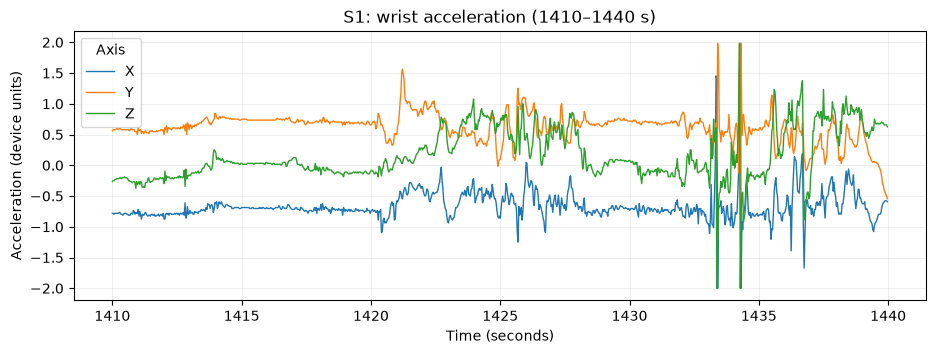

In [82]:
t_acc = np.arange(acc_start, acc_end) / ACC_HZ
plt.figure(figsize=(11, 3.5))
for i, axis in enumerate(["X", "Y", "Z"]):
    plt.plot(t_acc, acc[acc_start:acc_end, i], label=axis, linewidth=1)
plt.title(f"{SUBJECT}: wrist acceleration ({START}–{START + DURATION} s)")
plt.xlabel("Time (seconds)")
plt.ylabel("Acceleration (device units)")
plt.legend(title="Axis")
plt.grid(alpha=0.2)
plt.show()

# For table soccer, el spikes dyh 8albn lama byegy y-shoot bl la3eeb bta3o aw yosod aw kda
# wl 7arakat el fag2a el fy kol el axes dyh fl 8aleb byen2el mn rod le rod tanya

## 5. Explore reference heart rate

These labels were obtained from the chest ECG. We look at their distribution **only for understanding and later comparison**, not to estimate HR from PPG.

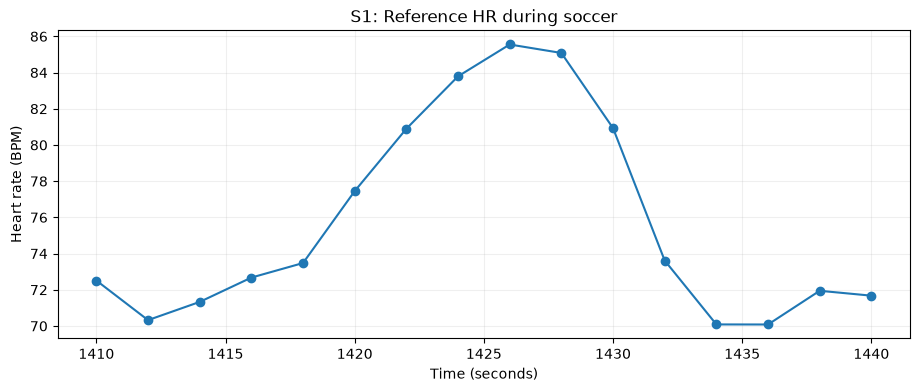

Mean HR: 75.71
Min HR: 70.08
Max HR: 85.55


In [ ]:
# Reference HR: 8-second windows, shifted by 2 seconds
t_hr = np.arange(len(reference_hr)) * 2 + 4

mask = (t_hr >= START) & (t_hr <= START + DURATION)

plt.figure(figsize=(11, 4))
plt.plot(t_hr[mask], reference_hr[mask], marker="o")

plt.title(f"{SUBJECT}: Reference HR during soccer")
plt.xlabel("Time (seconds)")
plt.ylabel("Heart rate (BPM)")
plt.grid(alpha=0.2)
plt.show()

print("Mean HR:", round(reference_hr[mask].mean(), 2))
print("Min HR:", round(reference_hr[mask].min(), 2))
print("Max HR:", round(reference_hr[mask].max(), 2))


# S1 wa2t el table soccer el average kan 75 3ady
# S1 wa2t el cycling el average kan 100 bpm

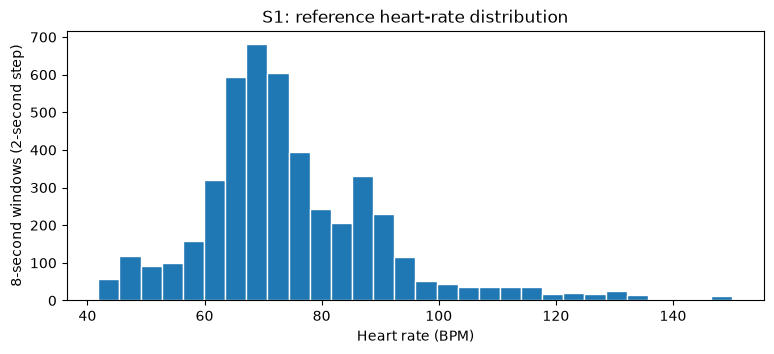

count    4603.0
mean       74.8
std        16.2
min        41.9
25%        65.5
50%        71.8
75%        83.3
max       150.2
Name: Reference HR (BPM), dtype: float64

In [ ]:
valid_hr = reference_hr[np.isfinite(reference_hr)]

plt.figure(figsize=(9, 3.5))
plt.hist(valid_hr, bins=30, edgecolor="white")
plt.title(f"{SUBJECT}: reference heart-rate distribution")
plt.xlabel("Heart rate (BPM)")
plt.ylabel("8-second windows (2-second step)")
plt.show()

display(pd.Series(valid_hr, name="Reference HR (BPM)").describe().round(1))
# bna5od el heart rate mn el gehaz el tany (el by2ees darabat el 2alb 3la tool) 3la window
# 8 thwany. w shift 2 kol mara. w h3mlna histogram lel kalam dh

## 6. Notes after running on the real data

Fill these in using **your own plots and printed results**:

- **Subject chosen and why:** …
- **Actual recording duration and any missing values:** …
- **What the PPG waveform looks like:** …
- **What acceleration looks like in the same segment:** …
- **Reference HR range and variation:** …
- **Limitations:** One participant is not representative; movement affects PPG; overlapping reference windows aren't independent; no medical conclusions.

**Next:** Develop the PPG-only heart-rate estimator in notebook 02.